# 5 · Sensitivity and uncertainty

With measured inputs, the bulk method overestimates the flux amplitude (Chapter 4). To identify the cause, the paper
varies one choice within the transfer coefficient at a time (stability scheme, scalar roughness ratio $\alpha_T$,
momentum roughness) and perturbs the two inputs, temperature difference and wind speed.

> [!NOTE]
> **Paper:** Sect. 4.2, Table 3, Fig. 7, Appendix C (Table C1), Table 2. **Code:** `fluxpy/sensitivity.py`
> (the configurations), `scripts/calc_bulk_and_ec_fluxes.py` (stages 3 and 4), `fluxpy/uncertainty.py` (Table 2),
> `scripts/make_manuscript_tables.py`.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
REPO = Path("..").resolve(); sys.path.insert(0, str(REPO))
plt.rcParams.update({"figure.dpi": 110, "figure.constrained_layout.use": True, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

AR  = REPO / "data/observations/ar"
FIG = xr.open_dataset(REPO / "data/model_output/sensitivity_figure_data.nc")      # all flux estimates, 90 segments
SEG = xr.open_dataset(AR / "analysis_ready_polar6_turbulent_fluxes_latest_5km.nc").sel(start_time=FIG.start_time.values)
EC  = FIG["H_obs_ec"].values

import logging; logging.disable(logging.INFO)
S = pd.read_csv(REPO / "data/model_output/sensitivity_summary_table.csv").set_index("label")
S = S[~S.index.str.contains("era5only")]

## Scalar roughness ratio $\alpha_T$

,slope (measured inputs),r (measured inputs),slope (MODIS + ERA5),r (MODIS + ERA5)
alpha_T,,,,
0e+00,0.6,0.7,0.3,0.5
0e+00,0.6,0.7,0.3,0.5
0e+00,0.7,0.7,0.3,0.5
0e+00,0.8,0.7,0.4,0.5
0e+00,0.8,0.7,0.4,0.5
0e+00,0.9,0.7,0.4,0.5
0e+00,1.0,0.7,0.5,0.5
0e+00,1.2,0.7,0.6,0.5
0e+00,1.3,0.7,0.6,0.5


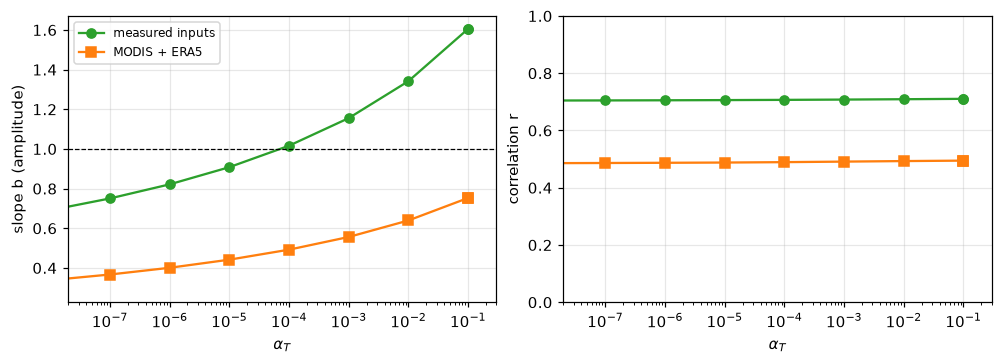

In [2]:
a = S[S.index.str.contains("ztr") | (S.index == "GLGS20_ref")].sort_values("zt_ratio")
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True)
for ax, col, ideal, lab in ((axs[0], "slope", 1, "slope b (amplitude)"), (axs[1], "r", None, "correlation r")):
    ax.semilogx(a.zt_ratio, a["obs_" + col], "o-", color="C2", label="measured inputs"); ax.semilogx(a.zt_ratio, a["rs_" + col], "s-", color="C1", label="MODIS + ERA5")
    if ideal: ax.axhline(ideal, color="k", ls="--", lw=0.8)
    ax.set_xlabel(r"$\alpha_T$"); ax.set_ylabel(lab)
axs[1].set_ylim(0, 1); axs[0].legend(fontsize=8); axs[0].set_xlim(2e-8, 0.3)
tab = a.drop_duplicates("zt_ratio")[["zt_ratio", "obs_slope", "obs_r", "rs_slope", "rs_r"]].round(1)
tab["zt_ratio"] = tab["zt_ratio"].map("{:.0e}".format)
tab.rename(columns={"zt_ratio": "alpha_T", "obs_slope": "slope (measured inputs)", "obs_r": "r (measured inputs)",
                    "rs_slope": "slope (MODIS + ERA5)", "rs_r": "r (MODIS + ERA5)"}).set_index("alpha_T")

With measured inputs, the amplitude is matched (slope 1) near $\alpha_T = 10^{-4}$, the *amplitude-matched
configuration* of the paper: three orders of magnitude below the conventional value and close to values found by earlier
aircraft measurements over sea ice. The correlation is unaffected, since roughness only rescales the flux (Chapter 3).

This is not interpreted as a measurement of $z_{0,T}$: any error that scales the flux, for instance in the surface
temperature, is absorbed by the same parameter. The value of $\alpha_T$ that gives the in-situ estimate the correct
amplitude further reduces the amplitude of the ERA5–MODIS estimate, which is already too small; a single $\alpha_T$
cannot correct both.

## Stability scheme and momentum roughness

In [3]:
groups = {"stability scheme (8 schemes)": S.index.str.endswith("_ref"),
          "alpha_T (1e-4 ... 1e-1)": (S.index.str.contains("ztr") & S.zt_ratio.between(1e-4, 1e-1)) | (S.index == "GLGS20_ref"),
          "momentum roughness set": S.index.str.contains("mosaic|sheba|nschnier") | (S.index == "GLGS20_ref"),
          "constant momentum roughness": S.index.str.contains("z0c")}
rng = lambda x: f"{x.min():.1f} - {x.max():.1f}"
pd.DataFrame({g: {"slope, measured inputs": rng(S[m].obs_slope), "r, measured inputs": rng(S[m].obs_r),
                  "slope, MODIS + ERA5": rng(S[m].rs_slope), "r, MODIS + ERA5": rng(S[m].rs_r)} for g, m in groups.items()}).T

,"slope, measured inputs","r, measured inputs","slope, MODIS + ERA5","r, MODIS + ERA5"
stability scheme (8 schemes),1.6 - 1.6,0.7 - 0.7,0.7 - 0.8,0.5 - 0.5
alpha_T (1e-4 ... 1e-1),1.0 - 1.6,0.7 - 0.7,0.5 - 0.8,0.5 - 0.5
momentum roughness set,1.6 - 1.8,0.7 - 0.7,0.7 - 0.8,0.5 - 0.5
constant momentum roughness,1.6 - 2.0,0.7 - 0.7,0.7 - 1.0,0.5 - 0.5


No choice within the transfer coefficient changes the correlation, and only the roughness lengths change the amplitude
appreciably. The eight stability schemes are practically indistinguishable: they share the functions for unstable
stratification and differ only under stable stratification, where the flux is small (Chapter 3).

## Sensitivity to the inputs

In [4]:
from fluxpy.uncertainty import central_difference, uncertainty_budget
keep = np.isfinite(EC); q = lambda x: f"{np.nanmedian(x):+.1f}  [{np.nanpercentile(x, 25):+.1f}, {np.nanpercentile(x, 75):+.1f}]"
pd.DataFrame({name: {"per +1 K in (theta_air - theta_s)   (W m-2)": q(central_difference(FIG, f"H_{k}_dTair", "dT")[keep]),
                     "per +1 m/s in wind speed   (W m-2)": q(central_difference(FIG, f"H_{k}_dU", "dU")[keep])}
              for k, name in (("obs", "measured inputs"), ("rs", "MODIS + ERA5"))}).T

,per +1 K in (theta_air - theta_s) (W m-2),per +1 m/s in wind speed (W m-2)
measured inputs,"-4.3 [-5.7, -1.0]","+0.0 [-0.3, +3.7]"
MODIS + ERA5,"-2.1 [-5.1, -0.4]","+0.2 [-0.8, +3.9]"


(Median and interquartile range over the segments.) A change of 1 K in the temperature difference has a much larger
effect than 1 m s⁻¹ in wind speed, and the typical air–surface temperature difference of one to two kelvin is comparable
to the uncertainty of a satellite surface temperature. The surface temperature product is therefore decisive (Chapter 4).

## Uncertainty budget (Table 2)

For the bulk fluxes, the assumed input uncertainties are propagated through the sensitivities above (first-order
Gaussian error propagation).

In [5]:
from fluxpy.uncertainty import INPUT_UNCERTAINTY
U = uncertainty_budget(FIG)
print("assumed 1-sigma input uncertainties (T_s [K], T_air [K], U [m/s]):", INPUT_UNCERTAINTY)
pd.DataFrame({name: [np.nanmedian(U[k]), np.nanpercentile(U[k], 25), np.nanpercentile(U[k], 75)]
              for k, name in (("ec_total", "EC reference"), ("obs_bulk", "bulk, measured inputs"), ("rs_bulk", "bulk, MODIS + ERA5"))},
             index=["median (W m-2)", "25th percentile", "75th percentile"]).round(1).T

assumed 1-sigma input uncertainties (T_s [K], T_air [K], U [m/s]): {'obs': (0.5, 0.3, 0.5), 'rs': (1.5, 1.2, 1.7)}


,median (W m-2),25th percentile,75th percentile
EC reference,0.8,0.2,1.6
"bulk, measured inputs",3.1,0.6,4.4
"bulk, MODIS + ERA5",8.8,1.6,11.8


**Summary.** The measured reference is known to about 1 W m⁻². A bulk estimate driven by satellite and reanalysis
inputs is uncertain by several W m⁻², more than the typical flux; surface temperature, air temperature and the large
ERA5 wind uncertainty contribute comparably. Whether an estimate follows the observed variability is determined by the
surface temperature (Chapter 4), its amplitude by the transfer coefficient; improving pan-Arctic flux estimates requires
both.